![illustration](notes/Kitaev-GME/figures/minimal-system_brick-wall_diagonal.svg)

In [1]:
from SpinModelDM import SpinSystem
DM = SpinSystem(thermo_limit=True, Jx=1/3, Jy=1/3, Jz=1/3)
DM.calculate_CorrTable(corr_table_sys_size=[60,60])

Creating CorrTable
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progress: 6/10
Progress: 7/10
Progress: 8/10
Progress: 9/10
Progress: 10/10
CorrTable creation complete


{'(-30,-60)AB': 2.887062484589087e-05,
 '(-30,-60)BA': 2.794717309236155e-05,
 '(-30,-60)AA': 0,
 '(-30,-60)BB': 0,
 '(-30,-59)AB': -4.353557817012733e-05,
 '(-30,-59)BA': 1.5312205716360032e-05,
 '(-30,-59)AA': 0,
 '(-30,-59)BB': 0,
 '(-30,-58)AB': 1.4627377519824491e-05,
 '(-30,-58)BA': -4.490545050000369e-05,
 '(-30,-58)AA': 0,
 '(-30,-58)BB': 0,
 '(-30,-57)AB': 3.062676995645506e-05,
 '(-30,-57)BA': 2.9597608450443368e-05,
 '(-30,-57)AA': 0,
 '(-30,-57)BB': 0,
 '(-30,-56)AB': -4.701631633827827e-05,
 '(-30,-56)BA': 1.7069500934300814e-05,
 '(-30,-56)AA': 0,
 '(-30,-56)BB': 0,
 '(-30,-55)AB': 1.6392135010364577e-05,
 '(-30,-55)BA': -4.847671944107409e-05,
 '(-30,-55)AA': 0,
 '(-30,-55)BB': 0,
 '(-30,-54)AB': 3.251606073334518e-05,
 '(-30,-54)BA': 3.136864984111019e-05,
 '(-30,-54)AA': 0,
 '(-30,-54)BB': 0,
 '(-30,-53)AB': -5.0899348792014776e-05,
 '(-30,-53)BA': 1.9093231036392676e-05,
 '(-30,-53)AA': 0,
 '(-30,-53)BB': 0,
 '(-30,-52)AB': 1.844075281181707e-05,
 '(-30,-52)BA': -5.24

# Confinement/Deconfinement Phase ('t Hooft loop testing)

L=2
Progress: Making Correlation Matrix
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progress: 6/10
Progress: 7/10
Progress: 8/10
Progress: 9/10
Progress: 10/10
L=4
Progress: Making Correlation Matrix
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progress: 6/10
Progress: 7/10
Progress: 8/10
Progress: 9/10
Progress: 10/10
L=6
Progress: Making Correlation Matrix
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progress: 6/10
Progress: 7/10
Progress: 8/10
Progress: 9/10
Progress: 10/10
L=8
Progress: Making Correlation Matrix
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progress: 6/10
Progress: 7/10
Progress: 8/10
Progress: 9/10
Progress: 10/10
L=10
Progress: Making Correlation Matrix
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progress: 6/10
Progress: 7/10
Progress: 8/10
Progress: 9/10
Progress: 10/10
L=12
Progress: Making Correlation Matrix
Pro

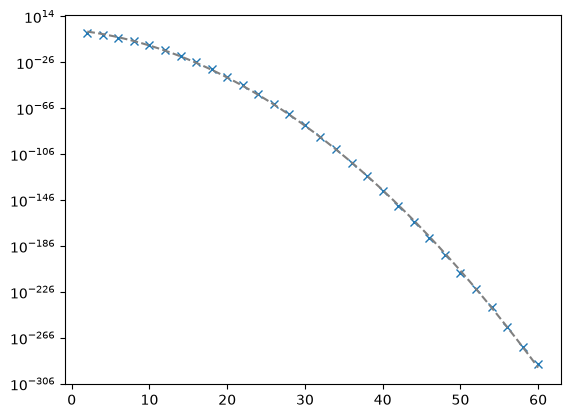

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from SpinModelDM_faster import SpinSystem, label_to_endpointset
from scipy.optimize import curve_fit
import os

largest_size = 60
DM = SpinSystem(thermo_limit=True, Jx=1/3, Jy=1/3, Jz=1/3)

edge_L_range = np.array([n for n in range(largest_size+1) if n%2==0 and n!=0])

update = True
if os.path.isfile('tHooft_loops.npy') and update==False:
    parity_data = np.load('tHooft_loops.npy')
else:
    parity_data = np.zeros_like(edge_L_range, dtype=float)
    count = 0
    for L in edge_L_range:
        DM.width = DM.height = L
        print(f'L={L}')
        [trodd, parity_data[count]] = DM.Coefficient_engine(label=int(DM.dim-1), 
                                                            corr_table_sys_size=[60,60])
        count += 1
    np.save('tHooft_loops', parity_data)

parity_data_ln = np.log(parity_data)

fitfunc = lambda x, a, b, c: a*x + b*x**2 + c
coes, err = curve_fit(fitfunc, edge_L_range, parity_data_ln)
[a_fit,b_fit,c_fit] = coes

print(f'a={a_fit}, b={b_fit}, c={c_fit}, error={err}')

plt.semilogy(edge_L_range, np.abs(parity_data), 'x')
L_range = np.linspace(edge_L_range[0], edge_L_range[-1], 200)
plt.semilogy(L_range, np.exp(fitfunc(L_range, a_fit, b_fit, c_fit)), '--', color='gray')

L=32, N=1024
Progress: Making Correlation Matrix
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progress: 6/10
Progress: 7/10
Progress: 8/10
Progress: 9/10
Progress: 10/10
L=34, N=1156
Progress: Making Correlation Matrix
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progress: 6/10
Progress: 7/10
Progress: 8/10
Progress: 9/10
Progress: 10/10
L=36, N=1296
Progress: Making Correlation Matrix
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progress: 6/10
Progress: 7/10
Progress: 8/10
Progress: 9/10
Progress: 10/10
L=38, N=1444
Progress: Making Correlation Matrix
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progress: 6/10
Progress: 7/10
Progress: 8/10
Progress: 9/10
Progress: 10/10
L=40, N=1600
Progress: Making Correlation Matrix
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progress: 6/10
Progress: 7/10
Progress: 8/10
Progress: 9/10
Progress: 10/10


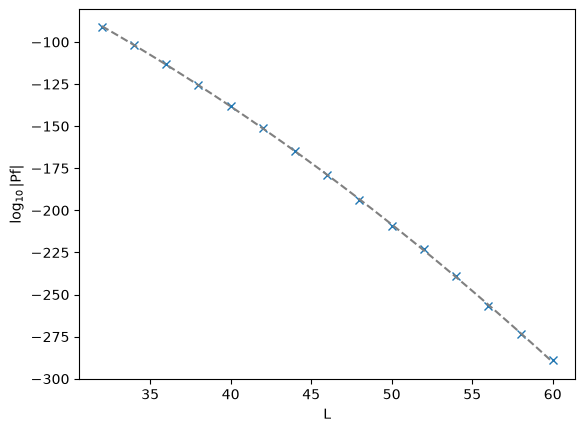

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from SpinModelDM_faster import SpinSystem, label_to_endpointset
from scipy.optimize import curve_fit
import os

largest_size = 60
DM = SpinSystem(thermo_limit=True, Jx=1/3, Jy=1/3, Jz=1/3)

edge_L_range = np.array([n for n in range(largest_size+1) if n%2==0 and n!=0 and n>30])

update = True
# NOTE: the cache now stores ln|Pf| (not Pf), hence the new file name.
cache_file = 'tHooft_loops_ln.npy'
if os.path.isfile(cache_file) and update==False:
    parity_data_ln = np.load(cache_file)
else:
    parity_data_ln = np.zeros_like(edge_L_range, dtype=float)
    count = 0
    for L in edge_L_range:
        DM.width = DM.height = L
        print(f'L={L}, N={DM.N}')   # (the 2^(L^2)-sized endpoint set is no longer printed)

        # label = dim-1 means every site is an endpoint, so the matrix is the full N x N one.
        # The CorrTable of the 60x60 system is read once and the matrix is filled by array indexing.
        DM.full_corr_mat_update(corr_table_sys_size=[60,60])

        # |Pf(M)|^2 = |det(M)|  ->  ln|Pf| = 0.5 * ln|det|; no overflow/underflow at N = 3600
        sign, logdet = np.linalg.slogdet(DM.full_corr_mat)
        parity_data_ln[count] = 0.5 * logdet
        count += 1
    np.save(cache_file, parity_data_ln)

fitfunc = lambda x, a, b, c: a*x + b*x**2 + c
coes, err = curve_fit(fitfunc, edge_L_range, parity_data_ln)
[a_fit,b_fit,c_fit] = coes

print(f'a={a_fit}, b={b_fit}, c={c_fit}, error={err}')

# same picture as semilogy(|Pf|), but drawn from ln|Pf| directly
plt.plot(edge_L_range, parity_data_ln / np.log(10), 'x')
L_range = np.linspace(edge_L_range[0], edge_L_range[-1], 200)
plt.plot(L_range, fitfunc(L_range, a_fit, b_fit, c_fit) / np.log(10), '--', color='gray')
plt.xlabel('L'); plt.ylabel(r'$\log_{10}|\mathrm{Pf}|$')
plt.show()
